In [5]:
%matplotlib inline
%precision 16

import numpy
import matplotlib.pyplot as plt
import scipy

Before you turn this problem in, make sure everything runs as expected. First, restart the kernel (in the menubar, select Kernel $\rightarrow$ Restart) and then run all cells (in the menubar, select Cell $\rightarrow$ Run All).

Make sure you fill in any place that says YOUR CODE HERE or "YOUR ANSWER HERE", as well as your name and collaborators below:

# HW 4: Initial Value Problems

## Question 1 - Lotka-Volterra

Consider the following system of equations
$$\begin{aligned}
    \frac{dp}{dt} &= b_0 \cdot p - d_0 \cdot p \cdot v \\
    \frac{dv}{dt} &= b_1 \cdot p \cdot v - d_1 \cdot v
\end{aligned}$$
where the unknown functions are $r(t)$ and $f(t)$ and $b_i, d_i \in \mathbb R^+$.  This system is commonly known as the Lotka-Volterra equations which model a simple predator-prey population model.  For our purposes the function $p(t)$ represents the population of tourists at the newly opened Jurassic Park (prey) and $v(t)$ the velociraptor population (predators).  Here we are also allowing the birth $b_i$ and death $d_i$ coefficients to vary in time with
$$
    b(t) = \begin{bmatrix}
        0.05 \cos^3(3 t / \pi) \\ 
        0.01 \sin^3(t / \pi)
    \end{bmatrix} \quad \quad \text{and} \quad \quad 
    d(t) = \begin{bmatrix}
        0.02 \cos(2 t / \pi) \\ 
        0.1 \sin(4 t / \pi)
    \end{bmatrix}
$$

**(a)** [5] Find the Jacobian of $f(t, u)$ and write a function that computes $f$ and the Jacobian $J$ given a $t$ and $u$.  Do not use `sympy` to write the Jacobian function although you can use it to check your answer.  We have provide the birth and death rate functions.

YOUR ANSWER HERE

In [3]:
def birth_rates(t):
    return numpy.array([0.05 * numpy.cos(t * 3.0 / numpy.pi)**3, 
                        0.01 * numpy.sin(t       / numpy.pi)**3])

def death_rates(t):
    return numpy.array([0.02 * numpy.cos(t * 2.0 / numpy.pi), 
                        0.10 * numpy.sin(t * 4.0 / numpy.pi)])

def f(t, U):
    """Right hand side of system."""

    return birth_rates(t) * U[0] * numpy.array([1, U[1]]) - death_rates(t) * U[1] * numpy.array([U[0], 1]);

def J(t, U):
    """Compute the Jacobian of the function f(t,u)"""

    res = numpy.column_stack((
        birth_rates(t) * numpy.array([1, U[1]]),
        death_rates(t) * numpy.array([-U[0], -1])
        ))
    res[0, 0] -= death_rates(t)[0] * U[1]
    res[1, 1] += birth_rates(t)[1] * U[0]

    return res
    

In [4]:
t = 1.0
U = numpy.array([32.0, 5.1])
f_solution = numpy.array([-2.316188606456715 , -0.4375625749832442])
numpy.testing.assert_allclose(f(t, U), f_solution)
J_solution = numpy.array([[-0.0723808939517723, -0.5146302900664267], [ 0.0015633065704327, -0.0857965833300479]])
numpy.testing.assert_allclose(J(t, U), J_solution)
print("Success!")

Success!


**(b)** [5] Use `scipy.integrate` to solve the system using the function you wrote above.

In [7]:
scipy.integrate.quad

<function scipy.integrate._quadpack_py.quad(func, a, b, args=(), full_output=0, epsabs=1.49e-08, epsrel=1.49e-08, limit=50, points=None, weight=None, wvar=None, wopts=None, maxp1=50, limlst=50, complex_func=False)>

In [14]:
scipy.integrate.odeint(lambda y, t: f(t, y), [4.0, 3.0], numpy.linspace(0, 0.1, 1000), Dfun=lambda y, t: J(t, y))

array([[4.                , 3.                ],
       [3.9959282921064956, 2.99808965074145  ],
       [3.9914492631134455, 2.9923978556096826],
       ...,
       [3.8800106066302953, 2.787792998427353 ],
       [3.865852562496156 , 2.7606839650448136],
       [3.8519914528516894, 2.733835371688376 ]])

In [17]:
def solve_scipy(t, U_0):
    """Solve the system using scipy.integrate"""
    
    res = scipy.integrate.odeint(lambda y, t: f(t, y), U_0, t, Dfun=lambda y, t: J(t, y), atol=1e-13, rtol=1e-13)
    
    return res

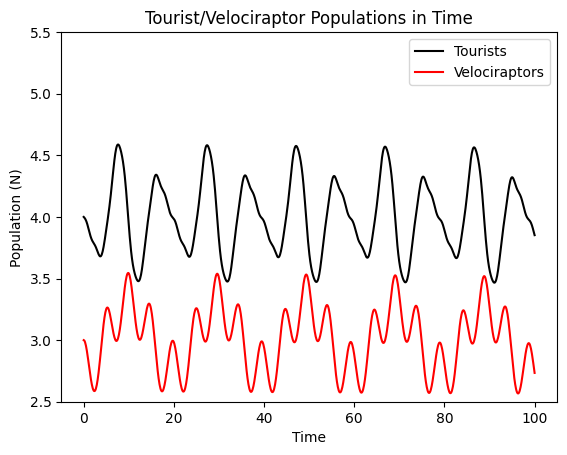

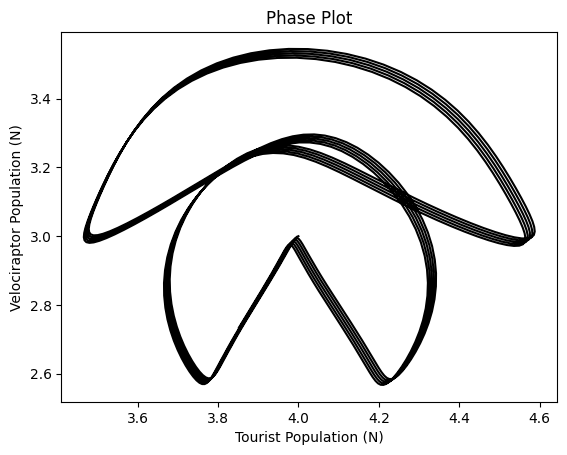

Success


In [19]:
t = numpy.linspace(0.0, 100.0, 1000)
U = solve_scipy(t, numpy.array([4.0, 3.0]))
U_true = numpy.array([[ 4.0,  3.0],
                      [ 3.9279172294167317,  3.5408818585097022],
                      [ 3.9830673083618886,  2.980274473969855 ],
                      [ 3.8004716403312524,  3.5000374537033361],
                      [ 3.9585778183108209,  2.9333231345441941],
                      [ 3.6950925707002193,  3.4300538999244909],
                      [ 3.9234384730566925,  2.8657982222073044],
                      [ 3.6145728074599934,  3.3401620269783758],
                      [ 3.8810111262801268,  2.7871140670350409],
                      [ 3.5554505511662997,  3.2417027488327261]])
numpy.testing.assert_allclose(U[::100], U_true)

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(t, U[:, 0], 'k', label="Tourists")
axes.plot(t, U[:, 1], 'r', label="Velociraptors")
axes.set_title("Tourist/Velociraptor Populations in Time")
axes.set_xlabel("Time")
axes.set_ylabel("Population (N)")
axes.set_ylim((2.5, 5.5))
axes.legend()

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(U[:, 0], U[:, 1], 'k')
axes.set_title("Phase Plot")
axes.set_xlabel("Tourist Population (N)")
axes.set_ylabel("Velociraptor Population (N)")

plt.show()
print("Success")

**(c)** [8] Consider the case where we wanted to use an implicit method, in this case backward Euler.  Since the function $f(t, u)$ is non-linear we must make some approximation to find the solution to the problem.  In the first case take the resulting ODE discretization and use a Taylor expansion of $f(t, u)$ about $(t^n, u(t^n))$ to find a new linear system that can be inverted to find the solution.  Write down this update scheme explicitly.

Hint: The eventual expression should be up to $\mathcal{O}(\Delta t)$.  Any higher order terms in $\Delta t$ can be dropped.

The schema of the backward Euler method is 

$$U^{(n+1)}-U^{(n)}=\Delta t f(t^{(n+1)}, U^{(n+1)}) = \Delta t f(t^{(n+1)}, U^{(n)}) + \Delta t J(t^{(n+1)}, U^{(n)})(U^{(n+1)}-U^{(n)}) + \mathcal{O}(\Delta t^2)$$

Hence, 

$$U^{(n+1)}\approx(I-\Delta t J(t^{(n+1)}, U^{(n)}))^{-1}(U^{(n)} + \Delta t f(t^{(n+1)}, U^{(n)})-\Delta t J(t^{(n+1)}, U^{(n)})U^{(n)})

In [20]:
numpy.identity(2)

array([[1., 0.],
       [0., 1.]])

**(d)** [7] Write a function that computes the solution to the linearized system of equations from part (c) using the backward Euler method.  You may use `numpy.linalg.solve`.

In [71]:
def solve_linearization(t, U_0):
    """Solve the Tourist/Velociraptor problem using a linearization"""

    h = t[1] - t[0]
    sol = numpy.array([U_0])

    for i in range(len(t) - 1):
        Un = sol[-1]
        left = numpy.identity(2) - h * J(t[i+1], Un)
        right = (Un + h * (f(t[i+1], Un) - J(t[i+1], Un) @ Un))
        tmp = numpy.linalg.solve(left, right)
        #tmp = Un + h * 
        sol = numpy.vstack([sol, tmp])
    
    return sol

In [72]:
t = numpy.linspace(0.0, 100.0, 1000)
U = solve_linearization(t, numpy.array([4.0, 3.0]))
U_true = numpy.array([[ 4.                ,  3.                ],
                      [ 3.9562704025807616,  3.5550168469660899],
                      [ 3.9946656738865847,  3.0008012236746606],
                      [ 3.8363199595503161,  3.5396965282316728],
                      [ 3.9822873402068408,  2.9733440899499959],
                      [ 3.7357914034866888,  3.4934127671296538],
                      [ 3.9586406842928703,  2.9233357150626329],
                      [ 3.6590999818099319,  3.424489869445619 ],
                      [ 3.9260233789064363,  2.8596477917259606],
                      [ 3.6040049623838342,  3.3438868112108282]])
print(U)
numpy.testing.assert_allclose(U[::100], U_true)

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(t, U[:, 0], 'k', label="Tourists")
#axes.plot(t[::100], U_true[:, 0], 'b', label="Tourists 2")
axes.plot(t, U[:, 1], 'r', label="Velociraptors")
#axes.plot(t[::100], U_true[:, 1], 'r', label="Velociraptors 2")
axes.set_title("Tourist/Velociraptor Populations in Time")
axes.set_xlabel("Time")
axes.set_ylabel("Population (N)")
axes.set_ylim((2.5, 5.5))
axes.legend()

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(U[:, 0], U[:, 1], 'k')
axes.set_title("Phase Plot")
axes.set_xlabel("Tourist Population (N)")
axes.set_ylabel("Velociraptor Population (N)")

plt.show()
print("Success")

[[4.                 3.                ]
 [3.967628606010859  2.992371979112326 ]
 [3.934577915806715  2.9772944387088898]
 ...
 [2.717856976984166  3.1406448213826494]
 [2.6830002999398332 3.079448418206201 ]
 [2.6505878812892254 3.0199541078263015]]


AssertionError: 
Not equal to tolerance rtol=1e-07, atol=0

Mismatched elements: 18 / 20 (90%)
Max absolute difference: 1.5632755489538162
Max relative difference: 0.4337606538476581
 x: array([[4.      , 3.      ],
       [3.520978, 5.032373],
       [3.70544 , 3.094919],...
 y: array([[4.      , 3.      ],
       [3.95627 , 3.555017],
       [3.994666, 3.000801],...

**(e)** [8] Again consider the use of backward Euler on the above system.  Now apply Newton's method to solve the system.  Formulate the approach mentioned writing down the eventual system of linear equations that need to be solved.  Make sure to explicitly write down this system.

YOUR ANSWER HERE

**(f)** [7] Implement the method you derived in (e).  You may use `numpy.linalg.solve`.

In [ ]:
def solve_newton(t, U_0, tolerance=1e-3):
    """"""

    # YOUR CODE HERE
    raise NotImplementedError()
    
    return U

In [ ]:
t = numpy.linspace(0.0, 100.0, 1000)
U = solve_newton(t, numpy.array([4.0, 3.0]), tolerance=1e-3)
print(repr(U[::100]))
U_true = numpy.array([[ 4.                ,  3.                ],
                      [ 3.9134711585015927,  3.5492962949915734],
                      [ 3.9930517703869257,  2.9903348084254571],
                      [ 3.7994886843948481,  3.5222458630304252],
                      [ 3.9768706240486029,  2.9540238459613501],
                      [ 3.7073585349850822,  3.4668124684596084],
                      [ 3.9494771605525214,  2.8980683829809037],
                      [ 3.6389102010408898,  3.3924679483427114],
                      [ 3.9153001879623379,  2.8320597734640938],
                      [ 3.5902204721540936,  3.310623730889021 ]])
numpy.testing.assert_allclose(U[::100], U_true)

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(t, U[:, 0], 'k', label="Tourists")
axes.plot(t, U[:, 1], 'r', label="Velociraptors")
axes.set_title("Tourist/Velociraptor Populations in Time")
axes.set_xlabel("Time")
axes.set_ylabel("Population (N)")
axes.set_ylim((2.5, 5.5))
axes.legend()

fig = plt.figure()
axes = fig.add_subplot(1, 1, 1)
axes.plot(U[:, 0], U[:, 1], 'k')
axes.set_title("Phase Plot")
axes.set_xlabel("Tourist Population (N)")
axes.set_ylabel("Velociraptor Population (N)")

plt.show()
print("Success")

**(g)** [5] How might you go about choosing an appropriate method for an approach to the problem?  Back up your decision with evidence.

YOUR ANSWER HERE

In [ ]:
# YOUR ANSWER HERE

## 2

Consider the following linearized model for a swinging pendulum with frictional forces included
$$
    \theta''(t) = -a \theta(t) - b \theta'(t).
$$

**(a)** [5] Write this as a system of ODEs and compute the eigenvalues of the matrix.  What do you observe if the damping is set to zero?

**Answer** Let $\varphi (t) = \theta'(t)$, then $\varphi'(t)=\theta''(t)$, hence

$$ \begin{bmatrix}
\varphi'(t)\\
\theta'(t) 
\end{bmatrix} = \begin{bmatrix}
-a\theta(t)-b\varphi(t)\\
\varphi(t)
\end{bmatrix} = \begin{bmatrix}
-b&-a\\
1 & 0
\end{bmatrix}\begin{bmatrix}
\varphi(t)\\
\theta(t) 
\end{bmatrix}$$

Let $A = \begin{bmatrix}
-b&-a\\
1 & 0
\end{bmatrix}$, then $|A-\lambda I|=0\ \Rightarrow\ \lambda = \dfrac{-b\pm\sqrt{b^2-4a}}{2}$

If the damping is set to zero, i.e. $b = 0$, then $\lambda$ the eigenvalues are pure imaginary, indicating that the pendulum will oscillate forever.


**(b)** [15] Implement the leapfrog, trapezoidal rule and the 2-step explicit Adams-Bashforth method AB2 to solve the ODE above.  Use forward RK2 to start the methods when applicable.

In [82]:
numpy.zeros(2)

array([0., 0.])

In [73]:
A = lambda a, b: numpy.array([[-b, -a], [1, 0]])
F = lambda t, U, a, b: A(a, b) @ U

In [85]:
def solve_leapfrog(t, U_0, a, b):
    """Solve the damped linear pendulum problem using the leapfrog method
    
    :Input:
     - *t* (ndarray(:)) - Time points to solve the ODE at.
     - *U_0* (ndarray(2)) - Initial condition.
     - *a* (float) - Spring constant.
     - *b* (float) - Damping constant.

    :Output:
     - (ndarray(2, :)) - Solution of ODE at values *t*.
    """
    
    h = t[1] - t[0]
    sol = numpy.zeros((len(t), len(U_0)))
    acc = numpy.zeros(len(t))
    sol[0, :] = numpy.array([U_0])
    acc[0] = -a * sol[0, 1] - b * sol[0, 0]
    for i in range(0, len(t) - 1):
        sol[i+1, 1] = sol[i, 1] + sol[i, 0] * h + 0.5 * acc[i] * h ** 2
        acc[i+1] = -a * sol[i+1, 1] - b * sol[i, 0]
        sol[i+1, 0] = sol[i, 0] + 0.5 * h * (acc[i] + acc[i+1])
    
    return sol.T


def solve_trap(t, U_0, a, b):
    """Solve the damped linear pendulum problem using the trapezoidal method
    
    :Input:
     - *t* (ndarray(:)) - Time points to solve the ODE at.
     - *U_0* (ndarray(2)) - Initial condition.
     - *a* (float) - Spring constant.
     - *b* (float) - Damping constant.

    :Output:
     - (ndarray(2, :)) - Solution of ODE at values *t*.
    """
    

    
    return U


def solve_AB2(t, U_0, a, b):
    """Solve the damped linear pendulum problem using 2-step Adams-Bashforth 
    
    :Input:
     - *t* (ndarray(:)) - Time points to solve the ODE at.
     - *U_0* (ndarray(2)) - Initial condition.
     - *a* (float) - Spring constant.
     - *b* (float) - Damping constant.

    :Output:
     - (ndarray(2, :)) - Solution of ODE at values *t*.
    """
    
    
    
    return U

In [86]:
t = numpy.linspace(0, 5.0, 500)
a = 10
b = 1
U_0 = numpy.array([numpy.pi / 2.0, 0.0])

# True solution
r = [0.5 * (-b + numpy.sqrt((b**2 - 4.0 * a) + 0.j)), 
     0.5 * (-b - numpy.sqrt((b**2 - 4.0 * a) + 0.j))]
C = [U_0[0] - U_0[0] / (1.0 - r[1] / r[0]), U_0[0] / (1.0 - r[1] / r[0])]
u_true = lambda t: C[0] * numpy.exp(r[0] * t) + C[1] * numpy.exp(r[1] * t)

U = solve_leapfrog(t, U_0, a, b)
error = numpy.linalg.norm((t[1] - t[0]) * (U[0, :] - u_true(t)), ord=1)
print("Error = %s" % error)
assert error < 1e-2
print("Success for Leapfrog!")

Error = 0.6290342167986595


AssertionError: 

In [ ]:
t = numpy.linspace(0, 5.0, 500)
a = 10
b = 1
U_0 = numpy.array([numpy.pi / 2.0, 0.0])

# True solution
r = [0.5 * (-b + numpy.sqrt((b**2 - 4.0 * a) + 0.j)), 
     0.5 * (-b - numpy.sqrt((b**2 - 4.0 * a) + 0.j))]
C = [U_0[0] - U_0[0] / (1.0 - r[1] / r[0]), U_0[0] / (1.0 - r[1] / r[0])]
u_true = lambda t: C[0] * numpy.exp(r[0] * t) + C[1] * numpy.exp(r[1] * t)

U = solve_trap(t, U_0, a, b)
error = numpy.linalg.norm((t[1] - t[0]) * (U[0, :] - u_true(t)), ord=1)
print("Error = %s" % error)
assert error < 1e-3
print("Success for trapezoidal method!")

In [ ]:
t = numpy.linspace(0, 5.0, 500)
a = 10
b = 1
U_0 = numpy.array([numpy.pi / 2.0, 0.0])

# True solution
r = [0.5 * (-b + numpy.sqrt((b**2 - 4.0 * a) + 0.j)), 
     0.5 * (-b - numpy.sqrt((b**2 - 4.0 * a) + 0.j))]
C = [U_0[0] - U_0[0] / (1.0 - r[1] / r[0]), U_0[0] / (1.0 - r[1] / r[0])]
u_true = lambda t: C[0] * numpy.exp(r[0] * t) + C[1] * numpy.exp(r[1] * t)

U = solve_AB2(t, U_0, a, b)
error = numpy.linalg.norm((t[1] - t[0]) * (U[0, :] - u_true(t)), ord=1)
print("Error = %s" % error)
assert error < 1e-2
print("Success for Adams-Bashforth 2!")

**(c)** [10] Test the leapfrog, trapezoid, and AB2 methods (all of which are second
order accurate) for each of the following cases (and perhaps others of your 
choice) and comment on the behavior of each method.  Instead of plotting $\theta$ plot the phase plane solution, i.e. plot $\theta(t)$ vs. $\theta'(t)$.  You can (and should) be careful about choosing $\Delta t$.

1. $a = 100, ~b=0$ (undamped),
1. $a = 100, ~b=3$ (damped),
1. $a = 100, ~b=10$ (more damped).

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

YOUR ANSWER HERE

## Question 3 - $R(z)$ for One-Step Methods

Any $r$-stage Runge-Kutta method applied to $u'=\lambda u$ will give an
expression of the form
$$
    U^{n+1} = R(z)U^n
$$
where $z=\lambda \Delta t$ and $R(z)$ is a rational function, a ratio of
polynomials in $z$ each having degree at most $r$.  For an explicit method
$R(z)$ will simply be a polynomial of degree $r$ and for an implicit method
it will be a more general rational function.

Since $u(t_{n+1}) = e^z u(t_n)$ for this problem, we expect that a $p$th
order accurate method will give a function $R(z)$ satisfying
$$
    R(z) = e^z + \mathcal{O}(z^{p+1}) \quad\text{as}~~~~z \rightarrow 0,
$$
as discussed in the Remark on page 129 of LeVeque.  The rational function $R(z)$ also
plays a role in stability analysis.

One can determine the value of $p$ in the last equation by expanding $e^z$ in a Taylor
series about $z=0$, writing the $\mathcal{O}(z^{p+1})$ term as
$$
    C z^{p+1} + \mathcal{O}(z^{p+2}),
$$
multiplying through by the denominator of $R(z)$, and then collecting terms.
For example, for the trapezoidal method
$$
    \frac{1+z/2}{1-z/2} = \left(1+z+\frac 1 2 z^2 + \frac 1 6 z^3 + \cdots\right) +Cz^{p+1} + \mathcal{O}(z^{p+2})
$$
gives
$$
    \begin{split}
        1+\frac{1}{2} z &= \left(1-\frac{1}{2} z\right)\left( 1+z+\frac{1}{2} z^2 + \frac 1 6 z^3 + \cdots\right) + Cz^{p+1} + \mathcal{O}(z^{p+2})\\
                  &= 1 + \frac{1}{2} z - \frac{1}{12} z^3 + \cdots + Cz^{p+1}  + \mathcal{O}(z^{p+2})
    \end{split}
$$
and so
$$
    Cz^{p+1} = \frac{1}{12} z^3 + \cdots,
$$
from which we conclude that $p=2$.

**(a)** [5] Let 
$$
    R(z) = \frac{1 + \frac 1 3 z}{1 - \frac 2 3 z + \frac 1 6 z^2}.
$$
Determine $p$ for this rational function as an approximation to $e^z$.

YOUR ANSWER HERE

**(b)** [10] Determine $R(z)$ and $p$ for the backward Euler method.

YOUR ANSWER HERE

**(c)** [10] Determine  $R(z)$ and $p$ for the TR-BDF2 given by
$$\begin{aligned}
    U^\ast &= U^n + \frac{\Delta t}{4} (f(U^n) + f(U^\ast)) \\
    U^{n+1} &= \frac{1}{3} (4 U^\ast - U^n + \Delta t f(U^{n+1})).
\end{aligned}$$
The name is comes from using a modified trapezoidal rule as the first stage and a two-step backwards difference formula for the second.

YOUR ANSWER HERE

**(d)** [7] Plot all of the above absolute stability regions.  Make sure to determine which denotes the interior and exterior of the region.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()